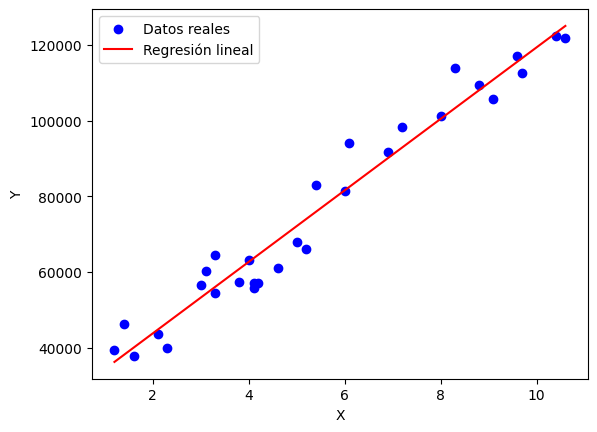

In [ ]:
import pandas as pd

# Leer el archivo CSV
df = pd.read_csv('Salary_dataset.csv', encoding='utf-8')
from sklearn.linear_model import LinearRegression
import matplotlib.pyplot as plt

# Mostrar las primeras filas
#display(df)




# Extraer las columnas (ajusta los nombres según tu CSV)
X = df[['YearsExperience']]  # Variable independiente
y = df['Salary']     # Variable dependiente

#regresion lineal
modelo = LinearRegression()
modelo.fit(X, y)  # Ajustar el modelo

# Predecir valores
y_pred = modelo.predict(X)

#grafico regresion lineal
plt.scatter(X, y, color='blue', label='Datos reales')
plt.plot(X, y_pred, color='red', label='Regresión lineal')
plt.xlabel('X')
plt.ylabel('Y')
plt.legend()
plt.show()

Ahora, implementaremos la regresión lineal utilizando el método del descenso de gradiente.

El descenso de gradiente es un algoritmo de optimización iterativo que busca minimizar una función de costo ajustando los parámetros del modelo en la dirección opuesta al gradiente de la función de costo con respecto a esos parámetros. En el caso de la regresión lineal, la función de costo es típicamente el Error Cuadrático Medio (MSE).

Parámetros finales (theta): [[24848.20396652]
 [ 9449.96232146]]
Costo final: 15635475.861140464


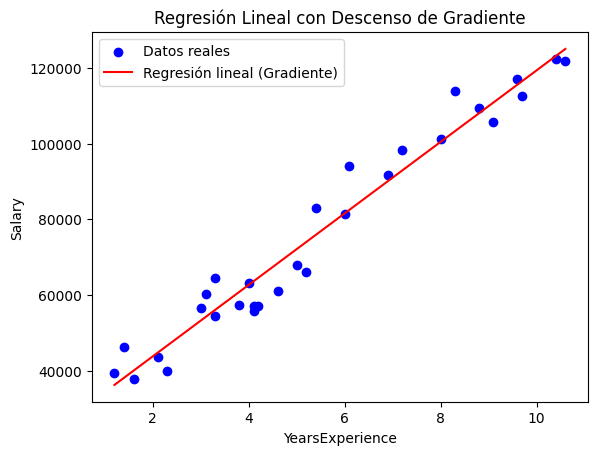

In [ ]:
# Definir la función de costo (Error Cuadrático Medio)
def compute_cost(X, y, theta):
    m = len(y)
    predictions = X.dot(theta)
    cost = (1 / (2 * m)) * np.sum(np.square(predictions - y))
    return cost

# Definir la función de descenso de gradiente
def gradient_descent(X, y, theta, alpha, num_iterations):
    m = len(y)
    cost_history = []

    for i in range(num_iterations):
        predictions = X.dot(theta)
        errors = np.subtract(predictions, y)
        sum_delta = (alpha / m) * X.transpose().dot(errors)
        theta = theta - sum_delta
        cost_history.append(compute_cost(X, y, theta))

    return theta, cost_history

# Preparar los datos para el descenso de gradiente
# Añadir una columna de unos a X para el término de intercepto
X_gd = np.c_[np.ones(X.shape[0]), X]
y_gd = y.values.reshape(-1, 1) # Asegurarse de que y sea un vector columna

# Inicializar parámetros (theta)
theta = np.zeros((X_gd.shape[1], 1))

# Definir hiperparámetros
alpha = 0.01  # Tasa de aprendizaje
num_iterations = 500000 # Número de iteraciones

# Ejecutar el descenso de gradiente
theta, cost_history = gradient_descent(X_gd, y_gd, theta, alpha, num_iterations)

print(f"Parámetros finales (theta): {theta}")
print(f"Costo final: {cost_history[-1]}")

# Predecir valores con los parámetros obtenidos
y_pred_gd = X_gd.dot(theta)

# Gráfico de la regresión lineal con descenso de gradiente
plt.scatter(X, y, color='blue', label='Datos reales')
plt.plot(X, y_pred_gd, color='red', label='Regresión lineal (Gradiente)')
plt.xlabel('YearsExperience')
plt.ylabel('Salary')
plt.title('Regresión Lineal con Descenso de Gradiente')
plt.legend()
plt.show()

Este código implementa el descenso de gradiente para encontrar los parámetros (pendiente e intercepto) de la regresión lineal que minimizan la función de costo. La gráfica muestra la línea de regresión obtenida por este método, que debería ser similar a la obtenida con `scikit-learn`.

In [ ]:
# Comparar los resultados de scikit-learn y descenso de gradiente

# Coeficientes y intercepto de scikit-learn (del modelo entrenado en la celda anterior)
print("Resultados con scikit-learn:")
print(f"Coeficiente (pendiente): {modelo.coef_[0]}")
print(f"Intercepto: {modelo.intercept_}")
print("-" * 30)

# Coeficientes y intercepto de descenso de gradiente
print("Resultados con Descenso de Gradiente:")
#theta[0] es el intercepto y theta[1] es el coeficiente de YearsExperience
print(f"Coeficiente (pendiente): {theta[1][0]}")
print(f"Intercepto: {theta[0][0]}")

#Calcular y comparar el Error Cuadrático Medio (MSE) para ambos modelos
from sklearn.metrics import mean_squared_error
import numpy as np

# MSE para scikit-learn
mse_sklearn = mean_squared_error(y, y_pred)
print(f"\nError Cuadrático Medio (MSE) con scikit-learn: {mse_sklearn}")

# MSE para descenso de gradiente
# Necesitamos y_pred_gd como un array 1D para mean_squared_error
mse_gd = mean_squared_error(y, y_pred_gd.flatten())
print(f"Error Cuadrático Medio (MSE) con Descenso de Gradiente: {mse_gd}")

Resultados con scikit-learn:
Coeficiente (pendiente): 9449.962321455077
Intercepto: 24848.203966523193
------------------------------
Resultados con Descenso de Gradiente:
Coeficiente (pendiente): 9449.962321455214
Intercepto: 24848.203966522262

Error Cuadrático Medio (MSE) con scikit-learn: 31270951.722280953
Error Cuadrático Medio (MSE) con Descenso de Gradiente: 31270951.722280927


Para la regresión lineal simple, scikit-learn es más eficiente y preciso. El descenso de gradiente es valioso para entender cómo funcionan los algoritmos de optimización y para aplicarlo a modelos más complejos. Ambos métodos llegaron a resultados muy similares en este caso, lo que valida tu implementación del descenso de gradiente

In [ ]:
print("Resultados con scikit-learn:")
print(f"Coeficiente (pendiente): {modelo.coef_[0]}")
print(f"Intercepto: {modelo.intercept_}")
print("-" * 30)

print("Resultados con Descenso de Gradiente:")
print(f"Coeficiente (pendiente): {theta[1][0]}")
print(f"Intercepto: {theta[0][0]}")

Resultados con scikit-learn:
Coeficiente (pendiente): 9449.962321455077
Intercepto: 24848.203966523193
------------------------------
Resultados con Descenso de Gradiente:
Coeficiente (pendiente): 9449.962321455214
Intercepto: 24848.203966522262



Los parámetros (coeficiente y intercepto) obtenidos de ambos métodos, scikit-learn y Descenso de Gradiente, son muy similares. La pequeña diferencia se debe principalmente a la naturaleza de los algoritmos. Scikit-learn utiliza un método analítico (ecuación normal) para encontrar la solución óptima directamente, lo que generalmente resulta en una mayor precisión numérica. El Descenso de Gradiente es un método iterativo que se aproxima a la solución óptima a lo largo de un número finito de iteraciones. Aunque se utilizaron 500,000 iteraciones y una tasa de aprendizaje de 0.01, es posible que no haya convergido exactamente al mismo punto que el método analítico debido a la precisión numérica y al criterio de parada (en este caso, un número fijo de iteraciones en lugar de un umbral de convergencia basado en el cambio en el costo o los parámetros). Sin embargo, la similitud de los resultados valida la implementación del Descenso de Gradiente.


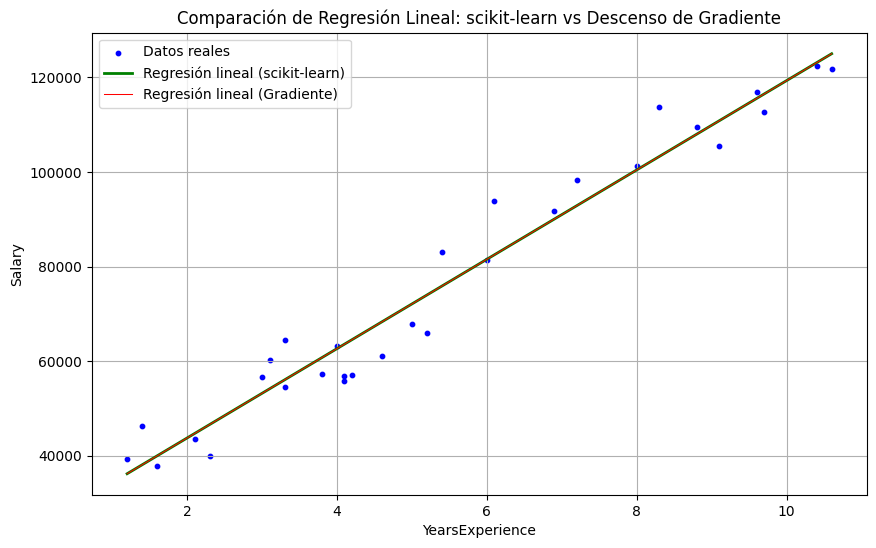

In [ ]:
plt.figure(figsize=(10, 6))

# Plot original data points
plt.scatter(X, y, color='blue', label='Datos reales', s=10) # Reduced dot size slightly for clarity

# Plot scikit-learn regression line
plt.plot(X, y_pred, color='green', label='Regresión lineal (scikit-learn)', linewidth=2) # Increased linewidth

# Plot Gradient Descent regression line
plt.plot(X, y_pred_gd, color='red', label='Regresión lineal (Gradiente)', linewidth=0.75) # Increased linewidth

# Add title and labels
plt.title('Comparación de Regresión Lineal: scikit-learn vs Descenso de Gradiente')
plt.xlabel('YearsExperience')
plt.ylabel('Salary')
plt.legend()
plt.grid(True)
plt.show()

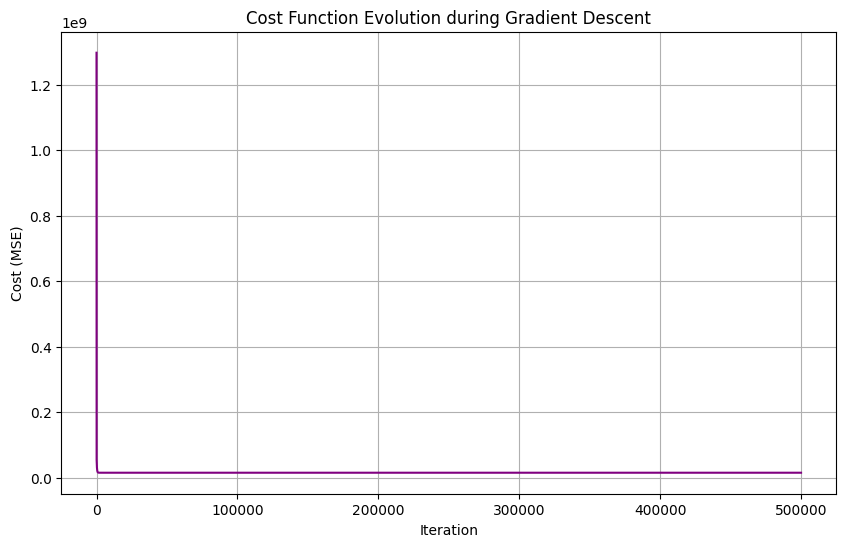

In [ ]:
# Plot the evolution of the cost function
plt.figure(figsize=(10, 6))
plt.plot(range(num_iterations), cost_history, color='purple')
plt.xlabel("Iteration")
plt.ylabel("Cost (MSE)")
plt.title("Cost Function Evolution during Gradient Descent")
plt.grid(True)
plt.show()

### Tercera Parte: Análisis y Clasificación de la Calidad de la Leche de Vaca

In [58]:
import pandas as pd
import numpy as np
import seaborn as sns
import plotly.express as px
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import accuracy_score, confusion_matrix
from sklearn.metrics import classification_report

,pH,Temprature,Taste,Odor,Fat,Turbidity,Colour,Grade
0,6.6,35,1,0,1,0,254,high
1,6.6,36,0,1,0,1,253,high
2,8.5,70,1,1,1,1,246,low
3,9.5,34,1,1,0,1,255,low
4,6.6,37,0,0,0,0,255,medium
...,...,...,...,...,...,...,...,...
1054,6.7,45,1,1,0,0,247,medium
1055,6.7,38,1,0,1,0,255,high
1056,3.0,40,1,1,1,1,255,low
1057,6.8,43,1,0,1,0,250,high


,pH,Temprature,Taste,Odor,Fat,Turbidity,Colour
count,1059.000000,1059.000000,1059.000000,1059.000000,1059.000000,1059.000000,1059.000000
mean,6.630123,44.226629,0.546742,0.432483,0.671388,0.491029,251.840415
std,1.399679,10.098364,0.498046,0.495655,0.469930,0.500156,4.307424
min,3.000000,34.000000,0.000000,0.000000,0.000000,0.000000,240.000000
25%,6.500000,38.000000,0.000000,0.000000,0.000000,0.000000,250.000000
50%,6.700000,41.000000,1.000000,0.000000,1.000000,0.000000,255.000000
75%,6.800000,45.000000,1.000000,1.000000,1.000000,1.000000,255.000000
max,9.500000,90.000000,1.000000,1.000000,1.000000,1.000000,255.000000


,Temprature
count,1059.000000
mean,44.226629
std,10.098364
min,34.000000
25%,38.000000
50%,41.000000
75%,45.000000
max,90.000000


,pH
count,1059.000000
mean,6.630123
std,1.399679
min,3.000000
25%,6.500000
50%,6.700000
75%,6.800000
max,9.500000


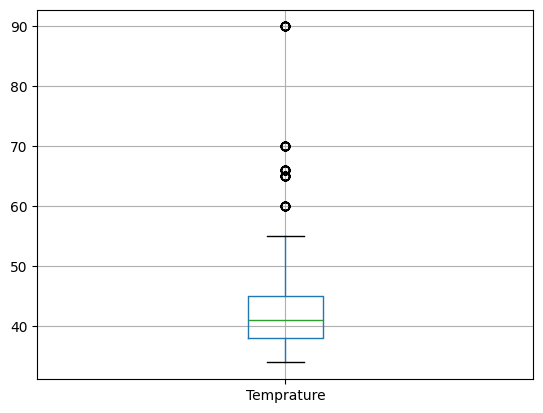

------------------


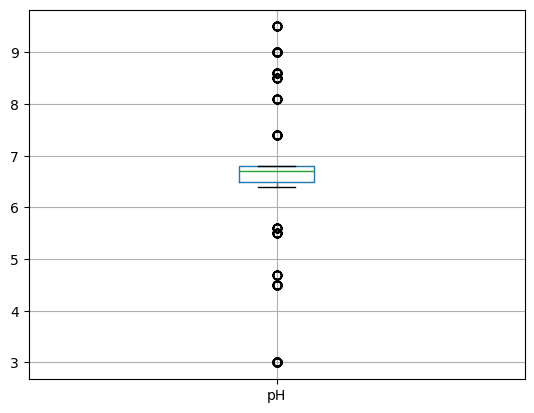

In [59]:
import pandas as pd
import matplotlib.pyplot as plt

# Leer el archivo CSV
df = pd.read_csv('milknew.csv', encoding='utf-8')
display(df)

display(df.describe())

display(df['Temprature'].describe())
display(df['pH'].describe())


#grafico boxplot
df.boxplot(column=['Temprature'])
plt.show()
print('------------------')
df.boxplot(column=['pH'])
plt.show()




Distribución de Grados después del mapeo:
Grade
0    429
1    374
2    256
Name: count, dtype: int64


,pH,Temprature,Taste,Odor,Fat,Turbidity,Colour,Grade
0,6.6,35,1,0,1,0,254,2
1,6.6,36,0,1,0,1,253,2
2,8.5,70,1,1,1,1,246,0
3,9.5,34,1,1,0,1,255,0
4,6.6,37,0,0,0,0,255,1


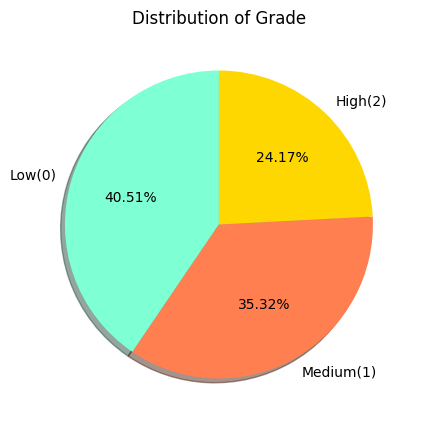

In [60]:
# Reload the dataset to ensure the 'Grade' column is read correctly as strings
df = pd.read_csv('milknew.csv', encoding='utf-8')

# Verificar primero si la columna existe
if 'Grade' in df.columns:
    # Limpiar los valores en la columna 'Grade' (eliminar espacios y convertir a minúsculas)
    df['Grade'] = df['Grade'].astype(str).str.strip().str.lower()

    # Mapear los valores
    df['Grade'] = df['Grade'].map({'low': 0, 'medium': 1, 'high': 2})

    # Mostrar conteo de valores para verificar
    print("Distribución de Grados después del mapeo:")
    print(df['Grade'].value_counts())

    # Mostrar las primeras filas
    display(df.head())
else:
    print("Error: La columna 'Grade' no existe en el DataFrame")

plt.figure(figsize=(5, 5))
# Create the pie chart
plt.pie(df["Grade"].value_counts(),
        labels=['Low(0)','Medium(1)','High(2)'],
        autopct='%.2f%%',
        startangle=90,
        colors=['aquamarine','coral','gold'],
        shadow=True)
plt.title('Distribution of Grade')
plt.show()

<Axes: >

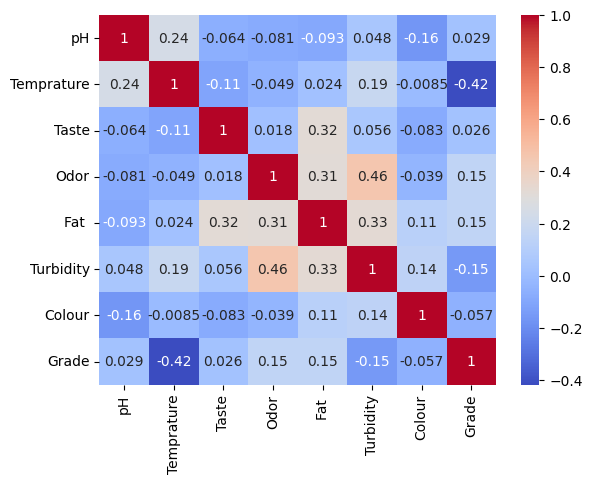

In [61]:
sns.heatmap(df.corr(), annot=True, cmap='coolwarm')

In [62]:
# Dividir los Datos
# X representa las características de entrada (todas las columnas excepto 'Grade')
X=df.drop(['Grade'],axis=1)
# y representa la variable objetivo ('Grade')
y=df['Grade']


# estandarizando con StandardScaler
# Crear una instancia del StandardScaler
sc=StandardScaler()
# Ajustar el escalador a los datos (calculando la media y la desviación estándar)
sc.fit(X)
# Transformar los datos utilizando la media y la desviación estándar calculadas
xscaled=sc.transform(X)
# Crear un DataFrame con las características escaladas
X_scaled=pd.DataFrame(data=xscaled,columns=X.columns)

print(X_scaled)

            pH  Temprature     Taste      Odor      Fat   Turbidity    Colour
0    -0.021531   -0.914107  0.910503 -0.872962  0.699608  -0.982217  0.501600
1    -0.021531   -0.815035 -1.098294  1.145525 -1.429372   1.018105  0.269333
2     1.336564    2.553438  0.910503  1.145525  0.699608   1.018105 -1.356536
3     2.051351   -1.013180  0.910503  1.145525 -1.429372   1.018105  0.733867
4    -0.021531   -0.715962 -1.098294 -0.872962 -1.429372  -0.982217  0.733867
...        ...         ...       ...       ...       ...        ...       ...
1054  0.049947    0.076620  0.910503  1.145525 -1.429372  -0.982217 -1.124269
1055  0.049947   -0.616889  0.910503 -0.872962  0.699608  -0.982217  0.733867
1056 -2.594765   -0.418744  0.910503  1.145525  0.699608   1.018105  0.733867
1057  0.121426   -0.121525  0.910503 -0.872962  0.699608  -0.982217 -0.427468
1058  1.408043    1.067347 -1.098294  1.145525  0.699608   1.018105  0.733867

[1059 rows x 7 columns]


In [157]:
#divide un conjunto de datos en datos de entrenamiento (X_train, y_train) y datos de prueba (X_test, y_test)
X_train, X_test, y_train, y_test = train_test_split(X_scaled, y, test_size=0.2, random_state=337)

In [158]:
#Para conocer la forma (dimensiones) del conjunto de entrenamiento y prueba.
print("X_train: ", X_train.shape, "\t y_train: ",y_train.shape)
print("X_test : ",X_test.shape, "\t y_test : ",y_test.shape)

X_train:  (847, 7) 	 y_train:  (847,)
X_test :  (212, 7) 	 y_test :  (212,)


In [159]:
# Instanciar un modelo de Regresión Logística
from sklearn.linear_model import LogisticRegression # Por defecto, usa: Regularización L2 (evita overfitting).

model = LogisticRegression(penalty='elasticnet', solver='saga', max_iter=1000, l1_ratio=0.3)

# Ajustar el modelo de Regresión Logística a los datos de entrenamiento
model.fit(X_train, y_train)

LogisticRegression(l1_ratio=0.3, max_iter=1000, penalty='elasticnet',
                   solver='saga')

El overfitting (sobreajuste) es un problema donde un modelo aprende demasiado bien los datos de entrenamiento, incluyendo su ruido y detalles irrelevantes, pero falla al generalizar a datos nuevos (no vistos).

**elasticnet**


Combina L1 y L2: Mezcla las propiedades de ambos (L1 para selección de features + L2 para manejar correlación entre variables).

Control ajustable: Usa el parámetro l1_ratio para definir la proporción de L1 vs L2.
Cuando hay correlación alta entre features (L2 ayuda a estabilizar el modelo).

solver='saga' cuando:

Necesites regularización l1 o elasticnet.

Trabajes con datasets grandes.

Requieras soporte para problemas multiclase.

Accuracy: 0.8538

Classification Report:
              precision    recall  f1-score   support

         low       0.87      0.90      0.88        87
      medium       0.89      0.86      0.88        73
        high       0.78      0.77      0.78        52

    accuracy                           0.85       212
   macro avg       0.85      0.84      0.84       212
weighted avg       0.85      0.85      0.85       212


Confusion Matrix:
[[78  4  5]
 [ 4 63  6]
 [ 8  4 40]]


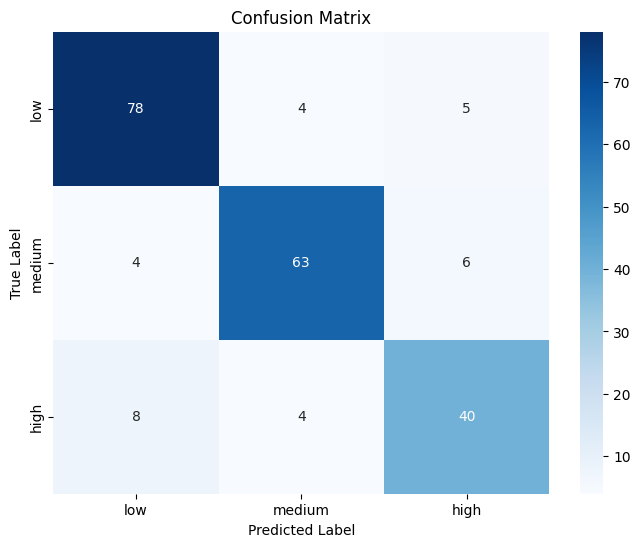

In [165]:
# Predecir en el conjunto de entrenamiento
y_pred = model.predict(X_test)

# Calcular accuracy
accuracy = accuracy_score(y_test, y_pred)
print(f"Accuracy: {accuracy:.4f}")

# Print classification report
print("\nClassification Report:")
print(classification_report(y_test, y_pred, target_names=['low', 'medium', 'high']))

# confusion matrix
cm = confusion_matrix(y_test, y_pred)
print("\nConfusion Matrix:")
print(cm)
# Visualize the confusion matrix
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['low', 'medium', 'high'], yticklabels=['low', 'medium', 'high'])
plt.title('Confusion Matrix')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.show()

In [163]:
from sklearn.metrics import accuracy_score

#Predecir en el conjunto de entrenamiento
y_train_pred = model.predict(X_train)

# Calcular accuracy en el conjunto de entrenamiento
train_accuracy = accuracy_score(y_train, y_train_pred)
print(f"Training Accuracy: {train_accuracy:.4f}")

# accuracy en el conjunto de prueba (test accuracy) ya fue calculada en el paso anterior
print(f"Test Accuracy: {accuracy:.4f}")

# Comparar accuracies
if train_accuracy > accuracy + 0.05: # Utilizando un umbral de 0.05 como indicador general
    print("\nThe model might be overfitted as the training accuracy is significantly higher than the test accuracy.")
elif accuracy > train_accuracy + 0.05:
     print("\nThe model might be underfitted as the test accuracy is significantly higher than the training accuracy.")
else:
    print("\nThe training and test accuracies are close, suggesting the model is not significantly overfitted or underfitted.")

Training Accuracy: 0.8536
Test Accuracy: 0.8538

The training and test accuracies are close, suggesting the model is not significantly overfitted or underfitted.


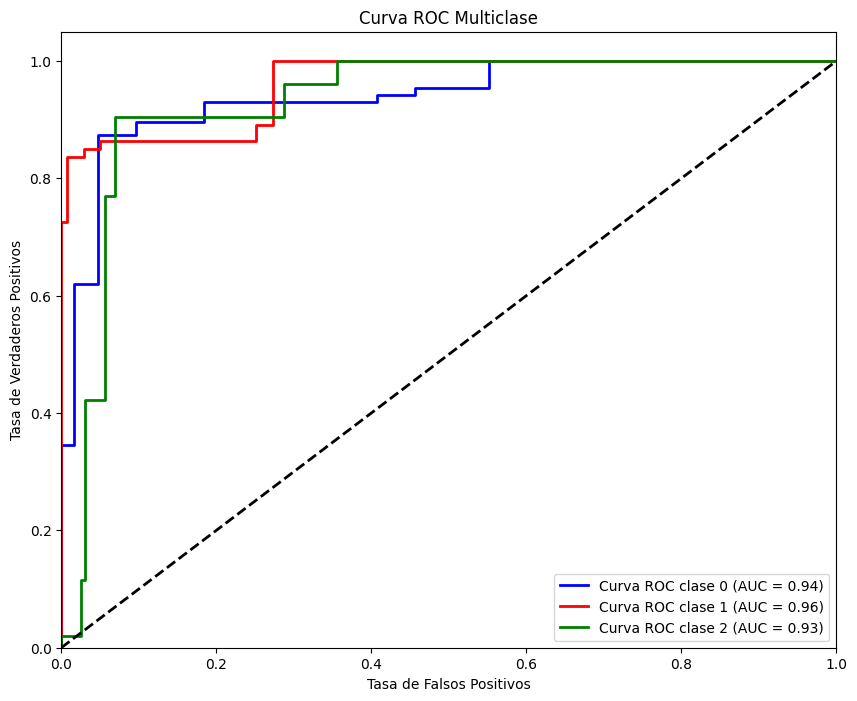

In [162]:
import numpy as np
from sklearn.metrics import roc_curve, auc
from sklearn.preprocessing import label_binarize
import matplotlib.pyplot as plt

# Binarizar la variable de destino para el enfoque One-vs-Rest
y_test_bin = label_binarize(y_test, classes=[0, 1, 2])
n_classes = y_test_bin.shape[1]

# Predecir las probabilidades para cada clase
y_score = model.predict_proba(X_test)

# Calcular la curva ROC y el área bajo la curva (AUC) para cada clase
fpr = dict()
tpr = dict()
roc_auc = dict()
for i in range(n_classes):
    fpr[i], tpr[i], _ = roc_curve(y_test_bin[:, i], y_score[:, i])
    roc_auc[i] = auc(fpr[i], tpr[i])

# Plotear las curvas ROC para cada clase
plt.figure(figsize=(10, 8))
colors = ['blue', 'red', 'green']
for i, color in zip(range(n_classes), colors):
    plt.plot(fpr[i], tpr[i], color=color, lw=2,
             label='Curva ROC clase {0} (AUC = {1:.2f})'.format(i, roc_auc[i]))

plt.plot([0, 1], [0, 1], 'k--', lw=2)
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('Tasa de Falsos Positivos')
plt.ylabel('Tasa de Verdaderos Positivos')
plt.title('Curva ROC Multiclase')
plt.legend(loc="lower right")
plt.show()

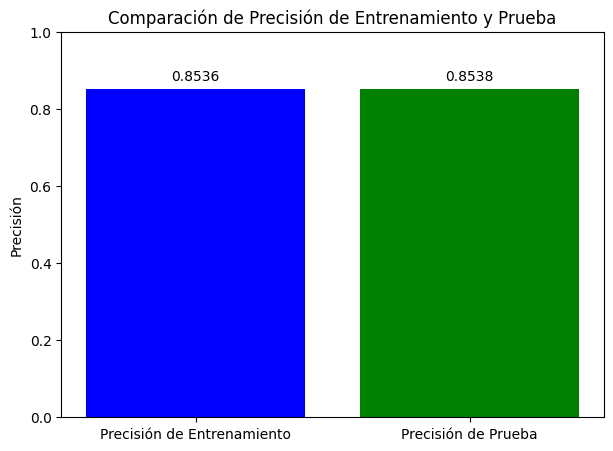

In [151]:
import matplotlib.pyplot as plt
import numpy as np



accuracies = [train_accuracy, accuracy]
labels = ['Precisión de Entrenamiento', 'Precisión de Prueba']
colors = ['blue', 'green']

plt.figure(figsize=(7, 5))
plt.bar(labels, accuracies, color=colors)
plt.ylabel('Precisión')
plt.title('Comparación de Precisión de Entrenamiento y Prueba')
plt.ylim([0, 1]) # La precisión va de 0 a 1

# Añadir los valores de precisión en las barras
for i, acc in enumerate(accuracies):
    plt.text(i, acc + 0.02, f'{acc:.4f}', ha='center')

plt.show()

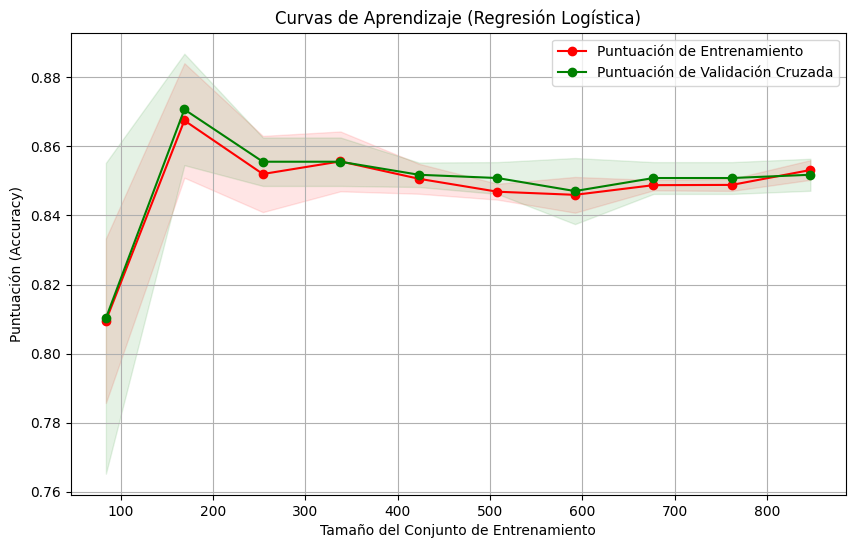

In [164]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import learning_curve

# Generar las curvas de aprendizaje
train_sizes, train_scores, test_scores = learning_curve(
    estimator=model,  # Tu modelo entrenado
    X=X_scaled,
    y=y,
    cv=5,  # Número de divisiones de validación cruzada
    scoring='accuracy',  # Métrica de evaluación
    n_jobs=-1,  # Usar todos los núcleos de CPU disponibles
    train_sizes=np.linspace(0.1, 1.0, 10) # Puntos en los que se calcula la curva
)

# Calcular las medias y desviaciones estándar de las puntuaciones
train_scores_mean = np.mean(train_scores, axis=1)
train_scores_std = np.std(train_scores, axis=1)
test_scores_mean = np.mean(test_scores, axis=1)
test_scores_std = np.std(test_scores, axis=1)

# Plotear las curvas de aprendizaje
plt.figure(figsize=(10, 6))
plt.fill_between(train_sizes, train_scores_mean - train_scores_std,
                 train_scores_mean + train_scores_std, alpha=0.1, color="r")
plt.fill_between(train_sizes, test_scores_mean - test_scores_std,
                 test_scores_mean + test_scores_std, alpha=0.1, color="g")
plt.plot(train_sizes, train_scores_mean, 'o-', color="r",
         label="Puntuación de Entrenamiento")
plt.plot(train_sizes, test_scores_mean, 'o-', color="g",
         label="Puntuación de Validación Cruzada")

plt.title("Curvas de Aprendizaje (Regresión Logística)")
plt.xlabel("Tamaño del Conjunto de Entrenamiento")
plt.ylabel("Puntuación (Accuracy)")
plt.legend(loc="best")
plt.grid()
plt.show()